In [ ]:
!pip -q install kaggle spacy nltk scikit-learn pandas matplotlib seaborn

import os
import re
import json
import glob
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
import spacy

from collections import Counter
from IPython.display import display

from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.sentiment import SentimentIntensityAnalyzer

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.feature_selection import chi2
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay
)

warnings.filterwarnings("ignore")

for resource in [
    "stopwords",
    "wordnet",
    "omw-1.4",
    "vader_lexicon",
    "punkt",
    "punkt_tab"
]:
    nltk.download(resource, quiet=True)

try:
    nlp = spacy.load("en_core_web_sm")
except OSError:
    !python -m spacy download en_core_web_sm
    nlp = spacy.load("en_core_web_sm")

print("NewsBot libraries loaded successfully!")

NewsBot libraries loaded successfully!


In [ ]:
from google.colab import files

uploaded = files.upload()

os.makedirs("/root/.kaggle", exist_ok=True)

if "kaggle.json" not in uploaded:
    raise ValueError("Please upload your kaggle.json file.")

with open("/root/.kaggle/kaggle.json", "wb") as f:
    f.write(uploaded["kaggle.json"])

os.chmod("/root/.kaggle/kaggle.json", 0o600)

!kaggle competitions download -c learn-ai-bbc -p /content/newsbot_data
!unzip -oq /content/newsbot_data/learn-ai-bbc.zip -d /content/newsbot_data

csv_files = glob.glob("/content/newsbot_data/**/*.csv", recursive=True)
print("Downloaded CSV files:")
for file in csv_files:
    print(os.path.basename(file))

Saving kaggle.json to kaggle.json
100% 1.85M/1.85M [00:00<00:00, 95.7MB/s]

Downloaded CSV files:
BBC News Sample Solution.csv
BBC News Test.csv
BBC News Train.csv


In [ ]:
train_path = next(
    (f for f in csv_files
     if "train" in os.path.basename(f).lower()
     and "sample" not in os.path.basename(f).lower()),
    None
)

if train_path:
    df = pd.read_csv(train_path)
else:
    bbc_path = next(
        (f for f in csv_files
         if os.path.basename(f).lower() == "bbc-text.csv"),
        None
    )
    if bbc_path is None:
        raise FileNotFoundError(
            "Could not find the BBC training CSV. Check the downloaded files."
        )
    df = pd.read_csv(bbc_path)

print("Original dataset shape:", df.shape)
print("Original columns:", df.columns.tolist())
display(df.head(3))

column_lookup = {c.lower().strip(): c for c in df.columns}

text_col = next(
    (column_lookup[c] for c in ["text", "article", "content"]
     if c in column_lookup),
    None
)
category_col = next(
    (column_lookup[c] for c in ["category", "label", "class"]
     if c in column_lookup),
    None
)

if text_col is None or category_col is None:
    raise ValueError(
        "Could not identify text/category columns. "
        "Review the column names printed above."
    )

df = df[[text_col, category_col]].rename(
    columns={text_col: "content", category_col: "category"}
)

df = df.dropna(subset=["content", "category"]).copy()
df["content"] = df["content"].astype(str).str.strip()
df["category"] = df["category"].astype(str).str.strip().str.lower()

df = df[
    (df["content"].str.len() > 100) &
    (df["category"] != "")
]
df = df.drop_duplicates(subset=["content"]).reset_index(drop=True)

if len(df) > 2000:
    df = df.groupby("category", group_keys=False).apply(
        lambda group: group.sample(
            n=min(len(group), max(1, int(2000 * len(group) / len(df)))),
            random_state=42
        )
    ).reset_index(drop=True)

print("\nPrepared dataset shape:", df.shape)
print("Number of categories:", df["category"].nunique())
print("\nCategory counts:")
print(df["category"].value_counts())

assert len(df) >= 500, "Dataset must contain at least 500 articles."
assert df["category"].nunique() >= 4, "Need at least 4 categories."
assert df[["content", "category"]].notna().all().all()

df.to_csv("/content/newsbot_dataset.csv", index=False)
print("\nClean dataset saved.")

Original dataset shape: (1490, 3)
Original columns: ['ArticleId', 'Text', 'Category']


,ArticleId,Text,Category
0,1833,worldcom ex-boss launches defence lawyers defe...,business
1,154,german business confidence slides german busin...,business
2,1101,bbc poll indicates economic gloom citizens in ...,business



Prepared dataset shape: (1440, 2)
Number of categories: 5

Category counts:
category
sport            342
business         335
politics         266
entertainment    263
tech             234
Name: count, dtype: int64

Clean dataset saved.


Business Case and application
----------------------------------------------------
Business problem: News organizations and business intelligence teams receive large amounts of news every day. Manually sorting articles, identifying key people and organizations, and tracking changes in sentiment takes time.

Proposed solution: NewsBot is an NLP-based news monitoring system that categorizes articles, extracts important entities, identifies sentiment, and highlights language patterns.

Target users: Journalists, media monitoring teams, researchers, and business analysts.

Business value: Faster article organization, easier trend discovery, more consistent monitoring, and support for research and decision-making.

Limitations: The BBC dataset contains five categories rather than all six example categories listed in the assignment. The system cannot classify a category it was never trained on, and sentiment scores should not be treated as verified facts or measures of news accuracy.

In [ ]:
stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

def preprocess_text(text):
    # Normalize text and remove URLs
    text = str(text).lower()
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)

    # Keep letters and spaces for the basic classification pipeline
    text = re.sub(r"[^a-z\s]", " ", text)
    tokens = nltk.word_tokenize(text)

    # Remove stop words and very short tokens, then lemmatize
    tokens = [
        lemmatizer.lemmatize(token)
        for token in tokens
        if token not in stop_words and len(token) > 1
    ]

    return " ".join(tokens)

df["clean_text"] = df["content"].apply(preprocess_text)

display(df[["content", "clean_text", "category"]].head(3))

print("Average original article length:",
      round(df["content"].str.split().str.len().mean(), 1), "words")

print("Average cleaned article length:",
      round(df["clean_text"].str.split().str.len().mean(), 1), "words")

# Save preprocessing output
df.to_csv("/content/newsbot_preprocessed.csv", index=False)

,content,clean_text,category
0,worldcom ex-boss launches defence lawyers defe...,worldcom ex bos launch defence lawyer defendin...,business
1,german business confidence slides german busin...,german business confidence slide german busine...,business
2,bbc poll indicates economic gloom citizens in ...,bbc poll indicates economic gloom citizen majo...,business


Average original article length: 385.2 words
Average cleaned article length: 215.3 words


TF-IDF matrix shape: (1440, 5000)
Vocabulary size: 5000


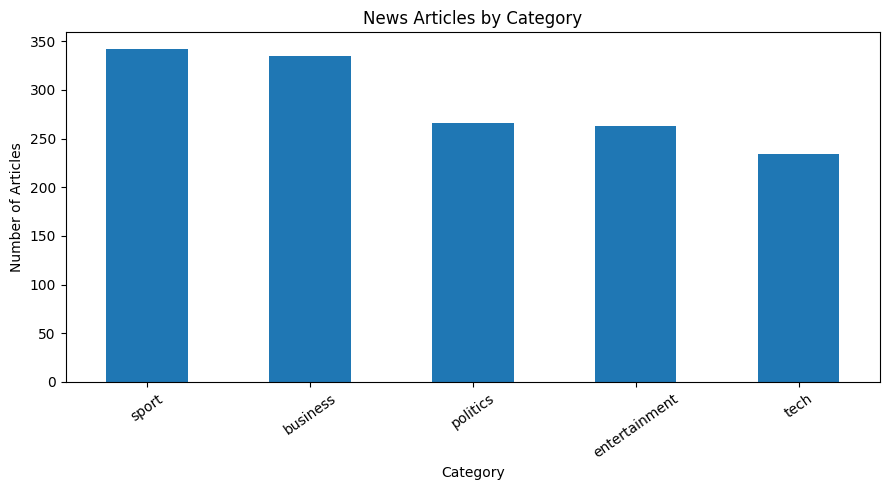


Top TF-IDF-associated terms for business:
bn, bank, growth, oil, profit, economy, share, bn bn, market, economic

Top TF-IDF-associated terms for entertainment:
film, award, actor, star, oscar, singer, album, band, actress, festival

Top TF-IDF-associated terms for politics:
labour, tory, election, blair, party, mr blair, minister, secretary, tony blair, conservative

Top TF-IDF-associated terms for sport:
match, champion, cup, coach, injury, season, chelsea, game, win, championship

Top TF-IDF-associated terms for tech:
user, software, computer, technology, mobile, microsoft, pc, web, online, digital


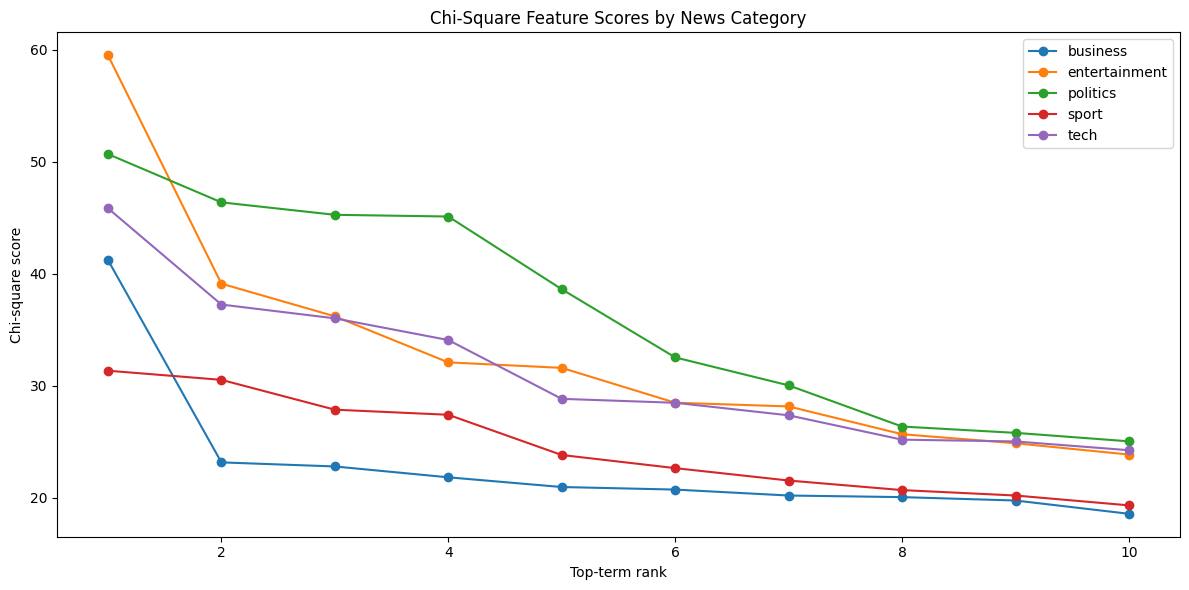

In [ ]:
tfidf = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95,
    sublinear_tf=True
)

X_tfidf = tfidf.fit_transform(df["clean_text"])
y = df["category"]

print("TF-IDF matrix shape:", X_tfidf.shape)
print("Vocabulary size:", len(tfidf.get_feature_names_out()))

plt.figure(figsize=(9, 5))
df["category"].value_counts().plot(kind="bar")
plt.title("News Articles by Category")
plt.xlabel("Category")
plt.ylabel("Number of Articles")
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()

terms = np.array(tfidf.get_feature_names_out())

plt.figure(figsize=(12, 6))

for category in sorted(df["category"].unique()):
    scores, _ = chi2(X_tfidf, y == category)
    top_indices = np.argsort(np.nan_to_num(scores))[-10:]
    top_indices = top_indices[np.argsort(
        np.nan_to_num(scores)[top_indices]
    )[::-1]]

    print(f"\nTop TF-IDF-associated terms for {category}:")
    print(", ".join(terms[top_indices]))

    plt.plot(
        range(1, 11),
        np.nan_to_num(scores)[top_indices],
        marker="o",
        label=category
    )

plt.title("Chi-Square Feature Scores by News Category")
plt.xlabel("Top-term rank")
plt.ylabel("Chi-square score")
plt.legend()
plt.tight_layout()
plt.show()

,NOUN,VERB,ADJ,ADV,PROPN
category,,,,,
business,0.245,0.116,0.076,0.027,0.077
entertainment,0.231,0.113,0.068,0.030,0.094
politics,0.224,0.131,0.072,0.030,0.071
sport,0.195,0.122,0.063,0.036,0.094
tech,0.247,0.128,0.081,0.035,0.045


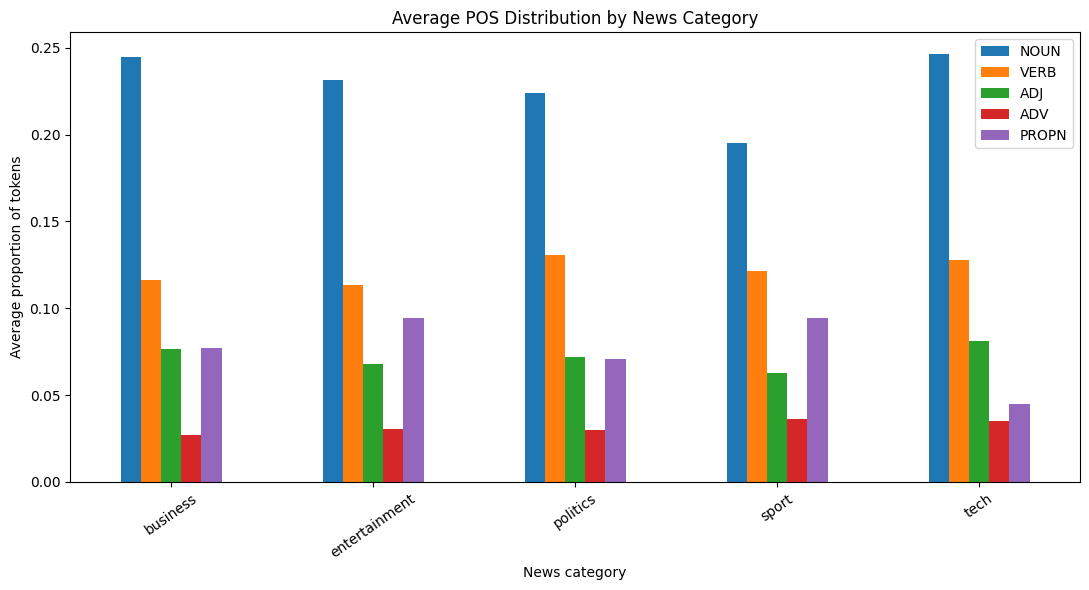

In [ ]:
sample_size = min(300, len(df))
pos_sample = df.sample(sample_size, random_state=42).copy()

def extract_pos(text):
    doc = nlp(text[:10000])

    counts = Counter(token.pos_ for token in doc if not token.is_space)
    total = sum(counts.values()) or 1

    return {
        "NOUN": counts["NOUN"] / total,
        "VERB": counts["VERB"] / total,
        "ADJ": counts["ADJ"] / total,
        "ADV": counts["ADV"] / total,
        "PROPN": counts["PROPN"] / total
    }

pos_results = pos_sample["content"].apply(extract_pos)
pos_df = pd.DataFrame(pos_results.tolist(), index=pos_sample.index)
pos_df["category"] = pos_sample["category"]

pos_by_category = pos_df.groupby("category")[
    ["NOUN", "VERB", "ADJ", "ADV", "PROPN"]
].mean()

display(pos_by_category.round(3))

pos_by_category.plot(kind="bar", figsize=(11, 6))
plt.title("Average POS Distribution by News Category")
plt.ylabel("Average proportion of tokens")
plt.xlabel("News category")
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()

In [ ]:
# Print the grammatical tags for one example article
example_doc = nlp(df.iloc[0]["content"][:3000])

print("Category:", df.iloc[0]["category"])
print("\nToken | Universal POS | Detailed tag")

for token in list(example_doc)[:40]:
    if not token.is_space:
        print(f"{token.text:20} | {token.pos_:12} | {token.tag_}")

Category: business

Token | Universal POS | Detailed tag
worldcom             | PROPN        | NNP
ex                   | PROPN        | NNP
-                    | NOUN         | NN
boss                 | NOUN         | NN
launches             | VERB         | VBZ
defence              | NOUN         | NN
lawyers              | NOUN         | NNS
defending            | VERB         | VBG
former               | ADJ          | JJ
worldcom             | PROPN        | NNP
chief                | PROPN        | NNP
bernie               | PROPN        | NNP
ebbers               | NOUN         | NNS
against              | ADP          | IN
a                    | DET          | DT
battery              | NOUN         | NN
of                   | ADP          | IN
fraud                | NOUN         | NN
charges              | NOUN         | NNS
have                 | AUX          | VBP
called               | VERB         | VBN
a                    | DET          | DT
company              | NOUN  

Average syntax features by category:


,sentence_count,token_count,average_sentence_length,noun_chunks,passive_tokens,root_verbs
category,,,,,,
business,15.43,369.23,24.01,87.60,5.81,15.43
entertainment,17.00,375.91,23.03,92.26,7.89,17.00
politics,19.08,470.12,24.66,118.10,10.58,19.08
sport,18.13,378.06,21.10,93.04,5.62,18.13
tech,24.18,565.38,23.93,141.26,12.14,24.18


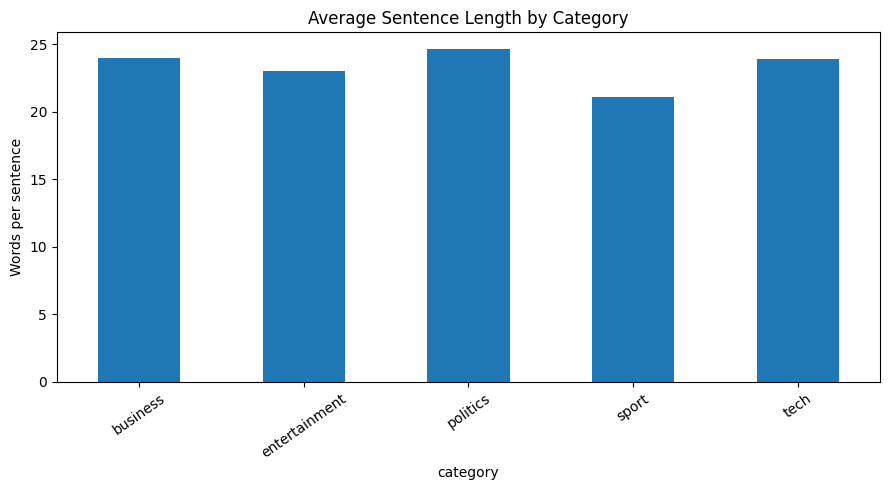

In [ ]:
def extract_syntax(text):
    doc = nlp(text[:5000])

    tokens = [t for t in doc if not t.is_space]
    sentences = list(doc.sents)

    return {
        "sentence_count": len(sentences),
        "token_count": len(tokens),
        "average_sentence_length": (
            len(tokens) / max(len(sentences), 1)
        ),
        "noun_chunks": len(list(doc.noun_chunks)),
        "passive_tokens": sum(
            1 for t in doc
            if t.dep_ in {"nsubjpass", "nsubj:pass", "auxpass"}
        ),
        "root_verbs": sum(1 for t in tokens if t.dep_ == "ROOT")
    }

syntax_sample = df.sample(min(300, len(df)), random_state=42).copy()

syntax_records = []
for idx, row in syntax_sample.iterrows():
    features = extract_syntax(row["content"])
    features["category"] = row["category"]
    syntax_records.append(features)

syntax_df = pd.DataFrame(syntax_records)

print("Average syntax features by category:")
display(
    syntax_df.groupby("category")
    .mean(numeric_only=True)
    .round(2)
)

syntax_df.groupby("category")["average_sentence_length"].mean().plot(
    kind="bar", figsize=(9, 5)
)
plt.title("Average Sentence Length by Category")
plt.ylabel("Words per sentence")
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()

In [ ]:
def extract_relationships(text):
    doc = nlp(text[:5000])
    relationships = []

    for token in doc:
        if token.pos_ != "VERB":
            continue

        subjects = [
            child.text for child in token.children
            if child.dep_ in {"nsubj", "nsubjpass", "nsubj:pass"}
        ]

        objects = [
            child.text for child in token.children
            if child.dep_ in {"dobj", "obj", "attr", "oprd"}
        ]

        if subjects:
            relationships.append({
                "subject": ", ".join(subjects),
                "action": token.lemma_,
                "object": ", ".join(objects) if objects else "(not identified)"
            })

    return relationships

example_article = df.iloc[0]["content"]
print("Article category:", df.iloc[0]["category"])

relationships = extract_relationships(example_article)
display(pd.DataFrame(relationships).head(15))

Article category: business


,subject,action,object
0,"-, boss",launch,lawyers
1,s,alert,directors
2,warnings,lead,(not identified)
3,ebbers,plead,(not identified)
4,lawyers,argue,(not identified)
5,ebbers,orchestrate,series
6,who,run,business
7,cooper,tell,jury
8,andersen,approve,accounting
9,she,say,(not identified)


Sentiment distribution:
sentiment
Positive    1013
Negative     416
Neutral       11
Name: count, dtype: int64


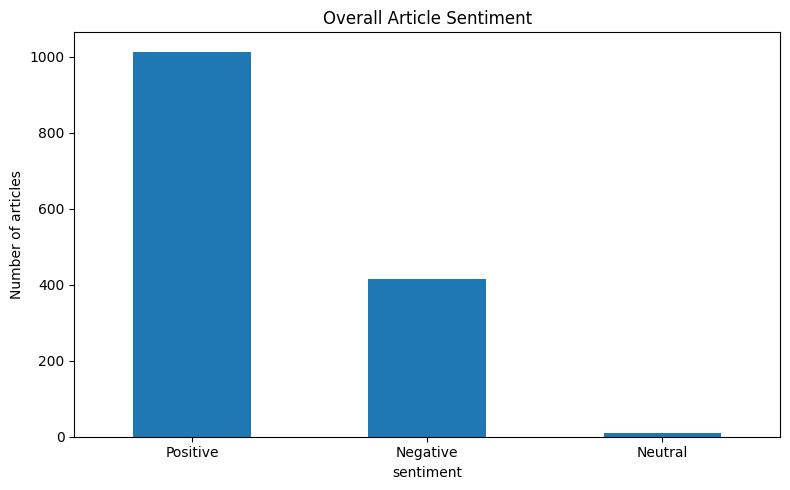

sentiment,Negative,Neutral,Positive
category,,,
business,0.364,0.015,0.621
entertainment,0.190,0.008,0.802
politics,0.466,0.004,0.530
sport,0.208,0.003,0.789
tech,0.209,0.009,0.782


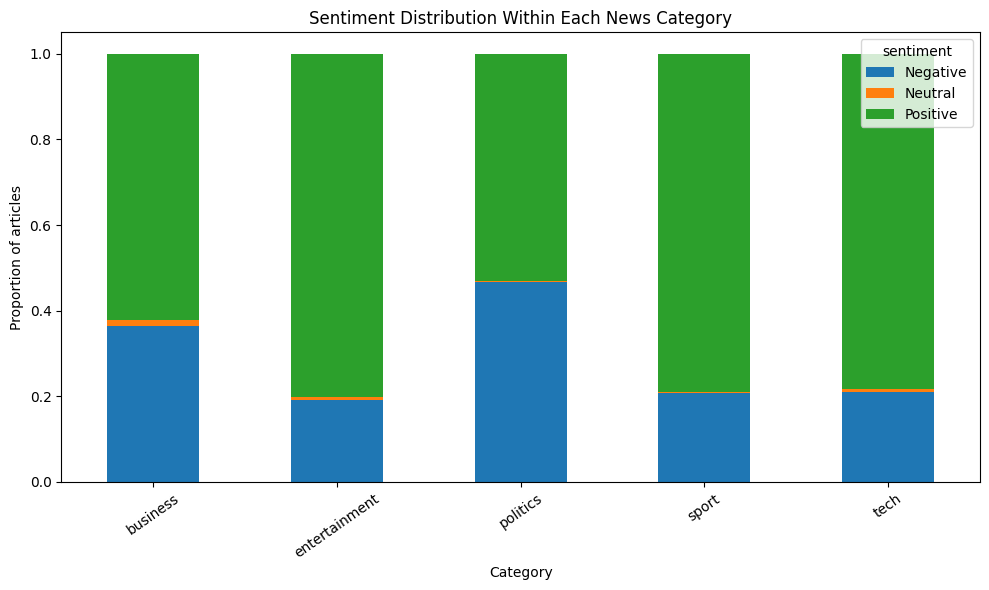

In [ ]:
sia = SentimentIntensityAnalyzer()

def analyze_sentiment(text):
    scores = sia.polarity_scores(str(text))
    compound = scores["compound"]

    if compound >= 0.05:
        label = "Positive"
    elif compound <= -0.05:
        label = "Negative"
    else:
        label = "Neutral"

    return pd.Series({
        "sentiment_score": compound,
        "positive_score": scores["pos"],
        "neutral_score": scores["neu"],
        "negative_score": scores["neg"],
        "sentiment": label
    })

sentiment_df = df["content"].apply(analyze_sentiment)
df = pd.concat([df, sentiment_df], axis=1)

print("Sentiment distribution:")
print(df["sentiment"].value_counts())

df["sentiment"].value_counts().plot(
    kind="bar", figsize=(8, 5)
)
plt.title("Overall Article Sentiment")
plt.ylabel("Number of articles")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

sentiment_table = pd.crosstab(
    df["category"], df["sentiment"], normalize="index"
)

display(sentiment_table.round(3))

sentiment_table.plot(
    kind="bar", stacked=True, figsize=(10, 6)
)
plt.title("Sentiment Distribution Within Each News Category")
plt.ylabel("Proportion of articles")
plt.xlabel("Category")
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()

,anger,fear,joy,sadness,trust
category,,,,,
business,0.030,0.104,0.033,0.009,0.233
entertainment,0.065,0.076,0.137,0.038,0.103
politics,0.068,0.414,0.053,0.019,0.575
sport,0.047,0.082,0.158,0.015,0.216
tech,0.026,0.175,0.073,0.013,0.256


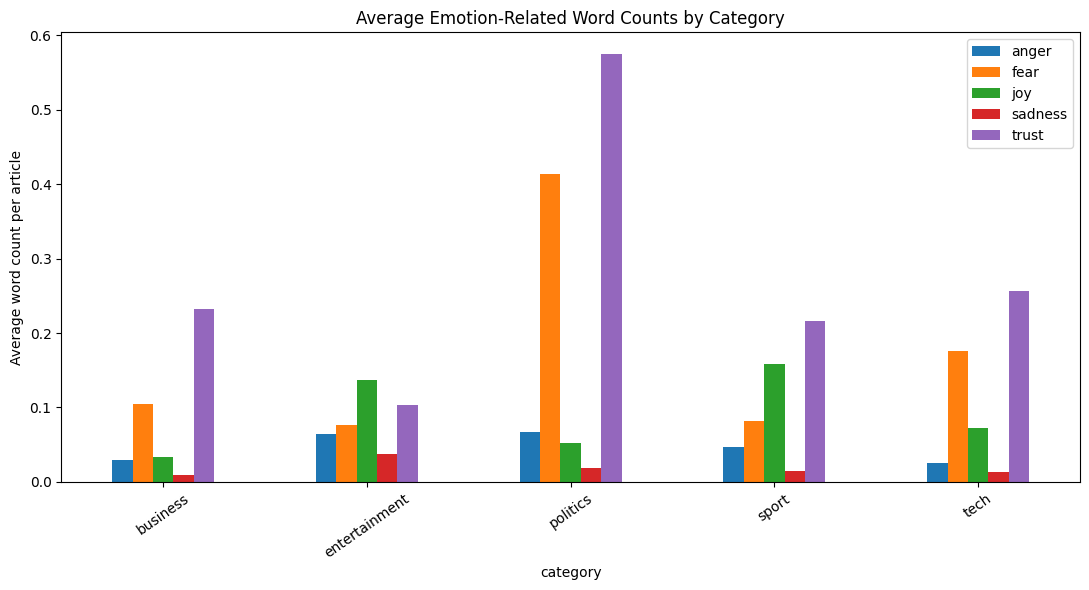

In [ ]:
emotion_words = {
    "anger": {
        "angry", "anger", "furious", "outrage", "hostile", "rage"
    },
    "fear": {
        "fear", "afraid", "threat", "danger", "terror", "worry"
    },
    "joy": {
        "happy", "happiness", "joy", "delight", "celebrate", "excited"
    },
    "sadness": {
        "sad", "sorrow", "grief", "tragic", "unhappy", "mourning"
    },
    "trust": {
        "trust", "confident", "reliable", "support", "faith", "secure"
    }
}

def count_emotions(text):
    words = re.findall(r"\b[a-z]+\b", str(text).lower())
    word_counts = Counter(words)

    return {
        emotion: sum(word_counts[word] for word in vocabulary)
        for emotion, vocabulary in emotion_words.items()
    }

emotion_sample = df[["content", "category"]].copy()

emotion_counts = pd.DataFrame(
    emotion_sample["content"].apply(count_emotions).tolist(),
    index=emotion_sample.index
)

emotion_counts["category"] = emotion_sample["category"]

emotion_by_category = emotion_counts.groupby("category")[
    list(emotion_words.keys())
].mean()

display(emotion_by_category.round(3))

emotion_by_category.plot(kind="bar", figsize=(11, 6))
plt.title("Average Emotion-Related Word Counts by Category")
plt.ylabel("Average word count per article")
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()


Training Logistic Regression...
Accuracy: 0.965
               precision    recall  f1-score   support

     business       0.94      0.99      0.96        67
entertainment       1.00      0.98      0.99        53
     politics       0.98      0.96      0.97        53
        sport       0.94      1.00      0.97        68
         tech       0.98      0.87      0.92        47

     accuracy                           0.97       288
    macro avg       0.97      0.96      0.96       288
 weighted avg       0.97      0.97      0.96       288


Training Naive Bayes...
Accuracy: 0.958
               precision    recall  f1-score   support

     business       0.93      0.97      0.95        67
entertainment       1.00      0.96      0.98        53
     politics       0.96      0.96      0.96        53
        sport       0.96      1.00      0.98        68
         tech       0.95      0.87      0.91        47

     accuracy                           0.96       288
    macro avg       0.96 

,Model,Accuracy
0,Linear SVM,0.972222
1,Logistic Regression,0.965278
2,Naive Bayes,0.958333


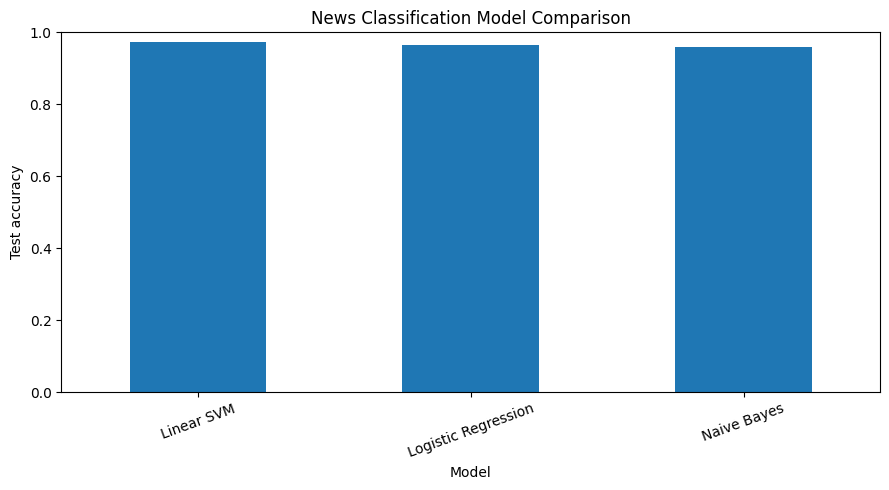

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    df["clean_text"],
    df["category"],
    test_size=0.20,
    random_state=42,
    stratify=df["category"]
)

models = {
    "Logistic Regression": Pipeline([
        ("tfidf", TfidfVectorizer(
            max_features=5000,
            ngram_range=(1, 2),
            min_df=2,
            max_df=0.95,
            sublinear_tf=True
        )),
        ("classifier", LogisticRegression(
            max_iter=2000,
            random_state=42
        ))
    ]),

    "Naive Bayes": Pipeline([
        ("tfidf", TfidfVectorizer(
            max_features=5000,
            ngram_range=(1, 2),
            min_df=2,
            max_df=0.95
        )),
        ("classifier", MultinomialNB())
    ]),

    "Linear SVM": Pipeline([
        ("tfidf", TfidfVectorizer(
            max_features=5000,
            ngram_range=(1, 2),
            min_df=2,
            max_df=0.95,
            sublinear_tf=True
        )),
        ("classifier", LinearSVC(random_state=42))
    ])
}

results = []
trained_models = {}

for name, model in models.items():
    print(f"\nTraining {name}...")
    model.fit(X_train, y_train)

    predictions = model.predict(X_test)
    accuracy = accuracy_score(y_test, predictions)

    trained_models[name] = model
    results.append({
        "Model": name,
        "Accuracy": accuracy
    })

    print(f"Accuracy: {accuracy:.3f}")
    print(classification_report(
        y_test, predictions, zero_division=0
    ))

results_df = pd.DataFrame(results).sort_values(
    "Accuracy", ascending=False
).reset_index(drop=True)

display(results_df)

results_df.plot(
    x="Model", y="Accuracy", kind="bar",
    legend=False, figsize=(9, 5)
)
plt.title("News Classification Model Comparison")
plt.ylabel("Test accuracy")
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

Best model: Linear SVM

Detailed evaluation:
               precision    recall  f1-score   support

     business       0.96      0.97      0.96        67
entertainment       0.98      0.98      0.98        53
     politics       0.96      0.96      0.96        53
        sport       0.99      1.00      0.99        68
         tech       0.98      0.94      0.96        47

     accuracy                           0.97       288
    macro avg       0.97      0.97      0.97       288
 weighted avg       0.97      0.97      0.97       288



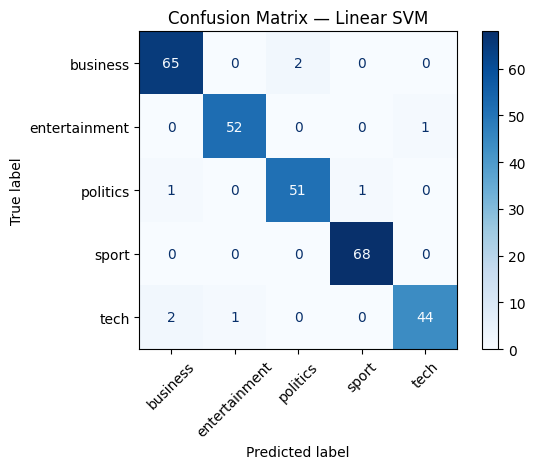

In [ ]:
best_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_name]

print("Best model:", best_name)

best_predictions = best_model.predict(X_test)

print("\nDetailed evaluation:")
print(classification_report(
    y_test, best_predictions, zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    best_predictions,
    xticks_rotation=45,
    cmap="Blues"
)
plt.title(f"Confusion Matrix — {best_name}")
plt.tight_layout()
plt.show()

In [ ]:
ner_sample = df.sample(
    min(500, len(df)), random_state=42
).copy()

entity_records = []

for row in ner_sample.itertuples():
    doc = nlp(row.content[:10000])

    for ent in doc.ents:
        entity_records.append({
            "category": row.category,
            "entity": ent.text.strip(),
            "entity_label": ent.label_
        })

entities_df = pd.DataFrame(
    entity_records,
    columns=["category", "entity", "entity_label"]
)

if not entities_df.empty:
    print("Entity counts by type:")
    display(entities_df["entity_label"].value_counts().head(15))

    entities_df["analysis_type"] = entities_df["entity_label"].replace({
        "LOC": "GPE"
    })

    target_types = ["PERSON", "ORG", "GPE", "DATE", "MONEY"]

    required_entities = entities_df[
        entities_df["analysis_type"].isin(target_types)
    ].copy()

    print("\nMost frequent entities:")
    display(
        required_entities.groupby(
            ["analysis_type", "entity"]
        ).size().sort_values(ascending=False).head(25).to_frame(
            "count"
        )
    )
else:
    required_entities = pd.DataFrame(
        columns=["category", "entity", "entity_label", "analysis_type"]
    )
    print("No entities were identified in this sample.")

Entity counts by type:


,count
entity_label,
DATE,2961
PERSON,2764
CARDINAL,2020
GPE,1877
ORG,1503
NORP,890
MONEY,681
ORDINAL,542
PERCENT,462



Most frequent entities:


count
analysis_type entity          
GPE           us           206
              uk           172
DATE          2004          98
              2005          91
GPE           london        84
              britain       81
DATE          last year     76
GPE           china         75
              france        74
ORG           bbc           70
PERSON        blair         70
GPE           europe        67
DATE          this year     61
GPE           england       57
DATE          2003          53
              tuesday       52
              sunday        49
ORG           microsoft     47
GPE           italy         46
              new york      45
              scotland      45
PERSON        eu            44
DATE          friday        42
              monday        41
              thursday      41

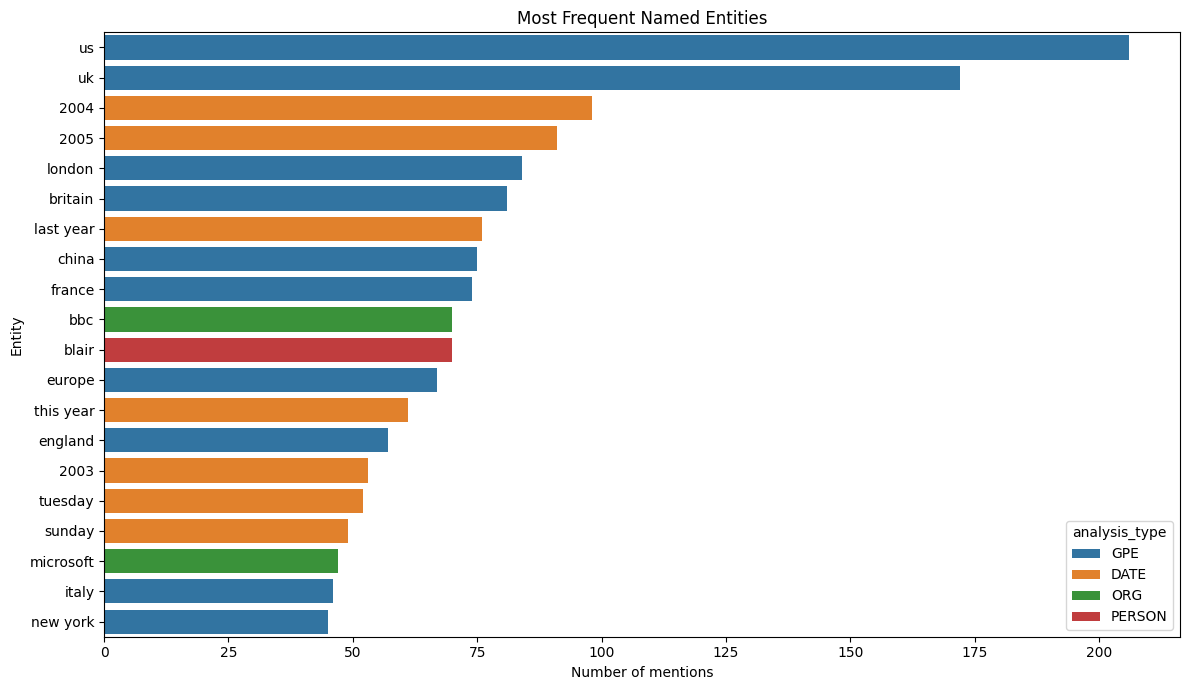

analysis_type,DATE,GPE,MONEY,ORG,PERSON
category,,,,,
business,904,701,357,546,384
entertainment,519,267,118,198,602
politics,440,320,111,184,666
sport,700,484,14,247,882
tech,398,252,81,328,230


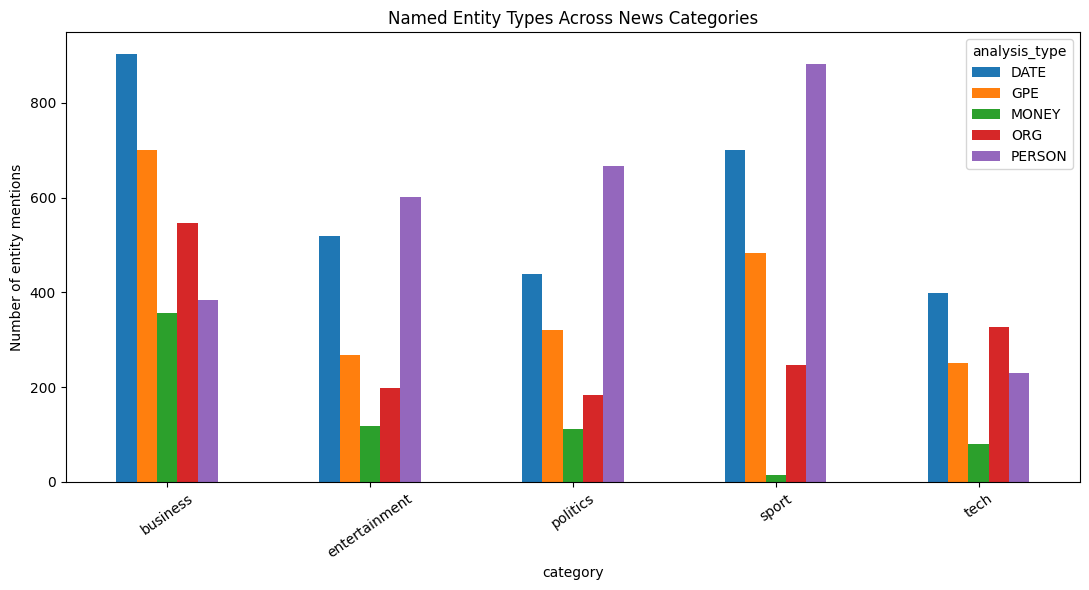

In [ ]:
if not required_entities.empty:
    top_entities = (
        required_entities.groupby(["analysis_type", "entity"])
        .size()
        .reset_index(name="count")
        .sort_values("count", ascending=False)
        .head(20)
    )

    plt.figure(figsize=(12, 7))
    sns.barplot(
        data=top_entities,
        x="count",
        y="entity",
        hue="analysis_type"
    )
    plt.title("Most Frequent Named Entities")
    plt.xlabel("Number of mentions")
    plt.ylabel("Entity")
    plt.tight_layout()
    plt.show()

    # Compare entity types across news categories
    entity_category_counts = pd.crosstab(
        required_entities["category"],
        required_entities["analysis_type"]
    )

    display(entity_category_counts)

    entity_category_counts.plot(
        kind="bar", figsize=(11, 6)
    )
    plt.title("Named Entity Types Across News Categories")
    plt.ylabel("Number of entity mentions")
    plt.xticks(rotation=35)
    plt.tight_layout()
    plt.show()

In [ ]:
from itertools import combinations

article_entity_sets = {}

for row in ner_sample.itertuples():
    doc = nlp(row.content[:10000])

    article_entities = sorted({
        ent.text.strip()
        for ent in doc.ents
        if ent.label_ in {"PERSON", "ORG", "GPE"}
        and len(ent.text.strip()) > 1
    })

    article_entity_sets[row.Index] = article_entities

pair_counts = Counter()

for article_entities in article_entity_sets.values():
    # Limit the number of entities per article to control pair growth
    limited_entities = article_entities[:20]

    for entity_a, entity_b in combinations(limited_entities, 2):
        pair_counts[(entity_a, entity_b)] += 1

relationship_df = pd.DataFrame([
    {
        "entity_1": pair[0],
        "entity_2": pair[1],
        "articles_together": count
    }
    for pair, count in pair_counts.most_common(20)
])

print("Most frequent entity co-occurrences:")
display(relationship_df)

Most frequent entity co-occurrences:


,entity_1,entity_2,articles_together
0,britain,uk,21
1,blair,tony blair,21
2,uk,us,21
3,london,uk,19
4,new york,us,14
5,britain,gordon brown,12
6,blair,gordon brown,11
7,blair,michael howard,11
8,blair,uk,11
9,england,scotland,11


In [ ]:
def analyze_news_article(article):

    cleaned = preprocess_text(article)

    predicted_category = best_model.predict([cleaned])[0]

    sentiment = analyze_sentiment(article)

    doc = nlp(article[:10000])

    entity_summary = {}
    for ent in doc.ents:
        label = "GPE" if ent.label_ == "LOC" else ent.label_

        if label in {"PERSON", "ORG", "GPE", "DATE", "MONEY"}:
            entity_summary.setdefault(label, []).append(ent.text)

    syntax = extract_syntax(article)
    relationships = extract_relationships(article)

    return {
        "Predicted category": predicted_category,
        "Sentiment": sentiment["sentiment"],
        "Sentiment score": round(
            sentiment["sentiment_score"], 3
        ),
        "Entities": entity_summary,
        "Syntax features": syntax,
        "Possible relationships": relationships[:10]
    }

example_article = df.iloc[0]["content"]

newsbot_result = analyze_news_article(example_article)

print("NEWSBOT ANALYSIS")
print("=" * 50)

for key, value in newsbot_result.items():
    print(f"\n{key}:")
    print(value)

NEWSBOT ANALYSIS

Predicted category:
business

Sentiment:
Negative

Sentiment score:
-0.97

Entities:
{'PERSON': ['cynthia cooper', 'arthur andersen', 'scott sullivan', 'sullivan'], 'GPE': ['us', 'new york'], 'DATE': ['2002', 'wednesday', 'early 2001 and', '2002', '2001', '85 years', '2004', 'last week'], 'MONEY': ['5.7bn', '6.75bn'], 'ORG': ['worldcom s accounting', 'mci', 'mci']}

Syntax features:
{'sentence_count': 15, 'token_count': 323, 'average_sentence_length': 21.533333333333335, 'noun_chunks': 83, 'passive_tokens': 1, 'root_verbs': 15}

Possible relationships:
[{'subject': '-, boss', 'action': 'launch', 'object': 'lawyers'}, {'subject': 's', 'action': 'alert', 'object': 'directors'}, {'subject': 'warnings', 'action': 'lead', 'object': '(not identified)'}, {'subject': 'ebbers', 'action': 'plead', 'object': '(not identified)'}, {'subject': 'lawyers', 'action': 'argue', 'object': '(not identified)'}, {'subject': 'ebbers', 'action': 'orchestrate', 'object': 'series'}, {'subject':

In [ ]:
import joblib

df.to_csv("/content/newsbot_final_results.csv", index=False)

entities_df.to_csv(
    "/content/newsbot_entities.csv", index=False
)

relationship_df.to_csv(
    "/content/newsbot_entity_relationships.csv", index=False
)

results_df.to_csv(
    "/content/newsbot_model_comparison.csv", index=False
)

joblib.dump(best_model, "/content/newsbot_model.joblib")

print("Saved project files:")
for filename in [
    "newsbot_dataset.csv",
    "newsbot_preprocessed.csv",
    "newsbot_final_results.csv",
    "newsbot_entities.csv",
    "newsbot_entity_relationships.csv",
    "newsbot_model_comparison.csv",
    "newsbot_model.joblib"
]:
    path = f"/content/{filename}"
    if os.path.exists(path):
        print(f" - {filename}")

Saved project files:
 - newsbot_dataset.csv
 - newsbot_preprocessed.csv
 - newsbot_final_results.csv
 - newsbot_entities.csv
 - newsbot_entity_relationships.csv
 - newsbot_model_comparison.csv
 - newsbot_model.joblib
